In [1]:
# =============================================================================
# Projeto: Análise de Recomendações Pedagógicas para o Uso de Inteligência
#          Artificial Generativa na Educação a Distância por meio de PLN e LLMs
# Disciplina: Inteligência Artificial - 7º N - Ciência da Computação
# Universidade Presbiteriana Mackenzie - Prof. Dr. Ivan Carlos Alcântara de Oliveira
# Integrante: Daniel Ribeiro Pauleti - RA 10723162 - 10723162@mackenzista.com.br
#
# Arquivo: notebooks/04_baseline_lexico_tfidf.ipynb
# Síntese: resultados parciais: baseline léxico com o livro de códigos (8 categorias),
#          TF-IDF + K-means (agrupamento) e geração da amostra estratificada para
#          anotação manual (validação humana).
#
# Histórico de alterações:
#   2026-09-25 - Daniel Ribeiro Pauleti - Versão inicial.
# =============================================================================

# 04 — Resultados parciais: baseline léxico, TF-IDF e agrupamento

1. **Baseline léxico** (regras): aplica os padrões do livro de códigos (`src/categorias.py`) e registra os termos que justificam cada rótulo.
2. **TF-IDF + K-means** (não supervisionado): agrupa os resumos em inglês e descreve cada grupo pelos termos de maior peso.
3. **Amostra para anotação manual**: amostra estratificada por ano e idioma, dividida em *desenvolvimento* (ajuste do prompt) e *teste* (avaliação final).

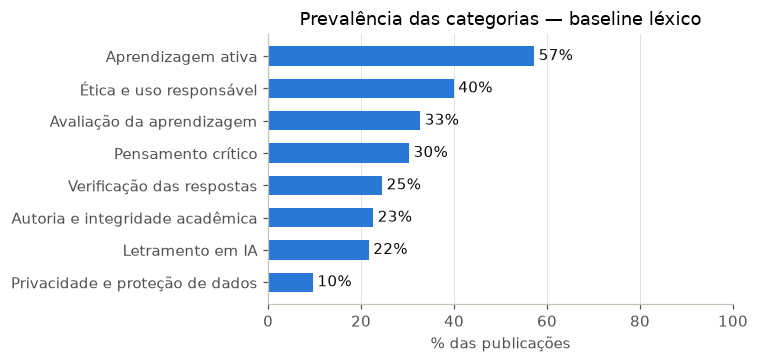

Categorias por documento: média = 2.38 | sem nenhuma categoria: 20


In [2]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.max_colwidth", 90)
import matplotlib.pyplot as plt
AZUL = "#2a78d6"                      # série única
PALETA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "font.family": "DejaVu Sans"})
FIG = RAIZ / "figuras"; FIG.mkdir(exist_ok=True)
def salvar(nome): plt.tight_layout(); plt.savefig(FIG / f"{nome}.png", bbox_inches="tight"); plt.show()
import numpy as np
from categorias import CATEGORIAS, CODIGOS, NOMES, matriz_lexica
corpus = pd.read_csv(RAIZ / "data/processed/corpus.csv")
M, evid = matriz_lexica(corpus)
prev = M.mean().rename(NOMES).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(prev.index, prev.values * 100, color=AZUL, height=0.6)
for y, v in zip(prev.index, prev.values): ax.text(v * 100 + 1, y, f"{v*100:.0f}%", va="center", color="#0b0b0b")
ax.set_xlim(0, 100); ax.set_xlabel("% das publicações"); ax.grid(axis="y", visible=False)
ax.set_title("Prevalência das categorias — baseline léxico")
salvar("fig5_prevalencia_lexico")
print("Categorias por documento: média =", M.sum(axis=1).mean().round(2),
      "| sem nenhuma categoria:", (M.sum(axis=1) == 0).sum())

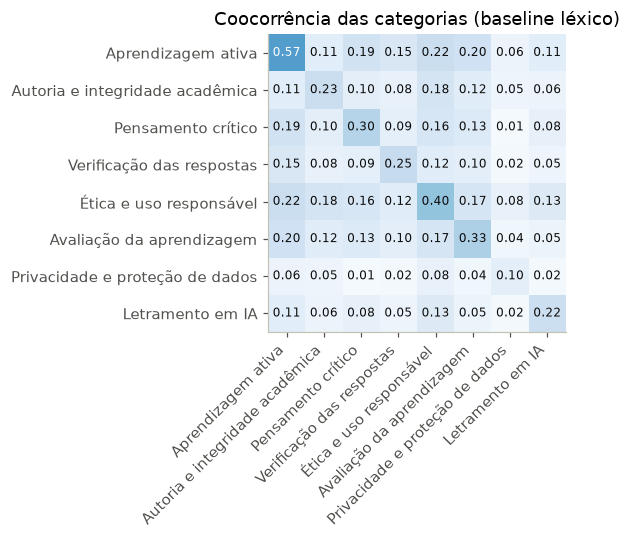

In [3]:
# Coocorrência entre categorias (proporção de documentos com ambas)
co = (M.T @ M) / len(M)
co.index = co.columns = [NOMES[c] for c in CODIGOS]
fig, ax = plt.subplots(figsize=(6.4, 5))
im = ax.imshow(co.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(8), co.columns, rotation=45, ha="right"); ax.set_yticks(range(8), co.index); ax.grid(False)
for i in range(8):
    for j in range(8):
        ax.text(j, i, f"{co.values[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if co.values[i, j] > 0.55 else "#0b0b0b")
ax.set_title("Coocorrência das categorias (baseline léxico)")
salvar("fig6_coocorrencia")

In [4]:
# Explicabilidade do baseline: termos que dispararam cada rótulo (exemplos)
ex = corpus.assign(evidencias=evid.map(lambda e: "; ".join(f"{k}: {', '.join(v)}" for k, v in e.items())))
ex[["titulo", "evidencias"]].head(5)

,titulo,evidencias
0,Challenging the Status Quo and Exploring the New Boundaries in the Age of Algorithms: ...,"APR_ATIVA: personaliz, tutor; PENS_CRITICO: overreliance; ETICA: bias, equit, transpar..."
1,Embracing the future of distance science education: Opportunities and challenges of Ch...,PENS_CRITICO: creativ; ETICA: responsib; LETRAMENTO: professional development
2,ChatGPT: An ever-increasing encroachment of artificial intelligence in online assessme...,AUTORIA: academic integrity; ETICA: ethic; AVALIACAO: assessment
3,Revitalizing Online Education: Leveraging Artificial Intelligence Tools for Dynamic an...,"APR_ATIVA: engagement, personalis, personaliz, tutor; ETICA: bias, ethic, responsib; P..."
4,Perspectives of the Use of ChatGPT as a Tool for Online Education of English,APR_ATIVA: personaliz


In [5]:
from collections import Counter
termos = {c: Counter(t for e in evid for t in e.get(c, [])).most_common(5) for c in CODIGOS}
pd.DataFrame({"categoria": [NOMES[c] for c in CODIGOS],
              "termos mais acionados": [", ".join(f"{t} ({n})" for t, n in termos[c]) for c in CODIGOS]})

,categoria,termos mais acionados
0,Aprendizagem ativa,"personaliz (48), engagement (48), feedback (40), tutor (31), personalis (17)"
1,Autoria e integridade acadêmica,"academic integrity (33), plagiar (5), autoria (4), cheat (4), disclos (3)"
2,Pensamento crítico,"critical thinking (20), creativ (17), reflection (12), reflective (10), higher-order (5)"
3,Verificação das respostas,"accuracy (19), reliab (14), hallucinat (9), accurate (8), verification (7)"
4,Ética e uso responsável,"ethic (49), responsib (22), equit (18), transparen (14), bias (10)"
5,Avaliação da aprendizagem,"assessment (45), assignment (13), grading (7), examination (7), avaliaç (4)"
6,Privacidade e proteção de dados,"privacy (14), security (5), surveillance (4), privacidade (1)"
7,Letramento em IA,"literac (15), professional development (10), ai literacy (8), prompting (4), formação ..."


## TF-IDF + K-means (resumos em inglês)

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import TruncatedSVD
dominio = {"ai", "artificial", "intelligence", "generative", "genai", "chatgpt", "gpt", "llm", "llms",
           "large", "language", "models", "model", "study", "research", "paper", "use", "using", "used",
           "results", "findings", "article", "based", "also", "chapter", "education", "educational",
           "learning", "students", "student", "higher", "distance", "online", "tools", "tool"}
en = corpus[corpus["idioma"] == "en"].reset_index(drop=True)
tfidf = TfidfVectorizer(stop_words=list(ENGLISH_STOP_WORDS | dominio), ngram_range=(1, 2), min_df=3, max_df=0.6,
                        sublinear_tf=True, token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z-]+\b")
X = tfidf.fit_transform(en["texto"])
print("Matriz TF-IDF:", X.shape)
# redução LSA (100 componentes) antes do K-means
svd = TruncatedSVD(n_components=100, random_state=42); Z = svd.fit_transform(X)
Z = Z / np.linalg.norm(Z, axis=1, keepdims=True)
print("Variância explicada (100 comp.):", svd.explained_variance_ratio_.sum().round(3))
sil = {k: silhouette_score(Z, KMeans(k, n_init=20, random_state=42).fit_predict(Z), metric="cosine") for k in range(4, 13)}
pd.Series(sil, name="silhueta").round(4).to_frame().T

Matriz TF-IDF: (182, 1831)
Variância explicada (100 comp.): 0.713


,4,5,6,7,8,9,10,11,12
silhueta,0.0228,0.0201,0.0178,0.015,0.0164,0.019,0.0181,0.023,0.032


In [7]:
K = 8   # igual ao número de categorias do livro de códigos, para permitir comparação
km = KMeans(K, n_init=20, random_state=42).fit(Z)
en["grupo"] = km.labels_
print("Silhueta (k=8):", round(sil[K], 4))
# termos de maior peso médio TF-IDF em cada grupo (descrição explicável do grupo)
nomes = tfidf.get_feature_names_out()
tops = {g: ", ".join(nomes[np.argsort(-X[en["grupo"].values == g].mean(axis=0).A1)[:8]]) for g in range(K)}
grupos = en.groupby("grupo").size().rename("docs").to_frame()
grupos["termos TF-IDF"] = pd.Series(tops)
grupos

Silhueta (k=8): 0.0164


,docs,termos TF-IDF
grupo,,
0,24,"challenges, potential, teaching, information, explores, technology, academic, open"
1,32,"odl, assessment, policy, open, digital, adaptive, review, engagement"
2,15,"analysis, teaching, methods, thematic, thematic analysis, academic, thinking, assessment"
3,17,"motivation, academic, quantitative, data, collected, data collected, survey, perceptions"
4,27,"process, technology, teacher, computer, teaching, technologies, school, development"
5,18,"gai, feedback, performance, course, support, enhance, university, group"
6,6,"digital assistant, assistant, i-aida, p-aida, privacy, digital, concerns, academic"
7,43,"framework, academic, course, systems, instructional, feedback, pedagogical, content"


In [8]:
# Relação entre grupos (K-means) e categorias (baseline léxico): % de docs do grupo com cada categoria
Men = M.loc[corpus["idioma"] == "en"].reset_index(drop=True)
rel = Men.groupby(en["grupo"]).mean().rename(columns=NOMES).round(2)
rel

,Aprendizagem ativa,Autoria e integridade acadêmica,Pensamento crítico,Verificação das respostas,Ética e uso responsável,Avaliação da aprendizagem,Privacidade e proteção de dados,Letramento em IA
grupo,,,,,,,,
0,0.58,0.17,0.25,0.21,0.21,0.12,0.04,0.33
1,0.66,0.28,0.28,0.09,0.47,0.41,0.16,0.25
2,0.47,0.33,0.53,0.20,0.40,0.40,0.00,0.07
3,0.53,0.12,0.18,0.18,0.47,0.12,0.06,0.41
4,0.56,0.22,0.41,0.33,0.30,0.41,0.00,0.22
5,0.72,0.06,0.39,0.39,0.33,0.17,0.11,0.06
6,0.50,1.00,0.17,0.00,0.67,0.17,0.83,0.00
7,0.67,0.19,0.23,0.42,0.37,0.51,0.12,0.07


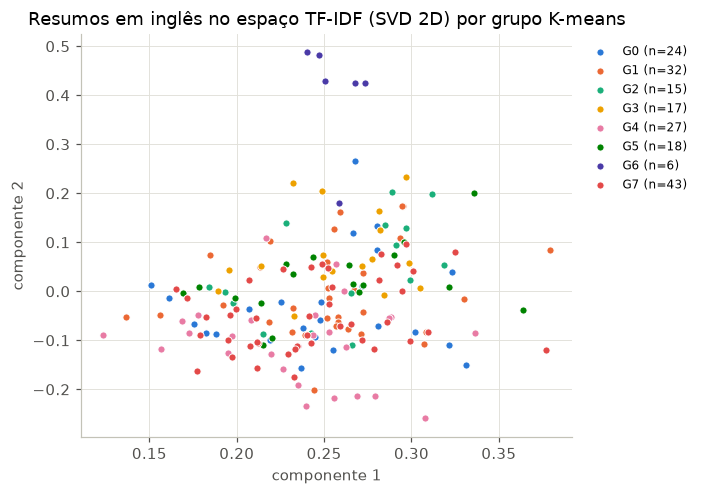

In [9]:
# Projeção 2D (SVD) dos documentos coloridos por grupo
P = TruncatedSVD(n_components=2, random_state=42).fit_transform(X)
fig, ax = plt.subplots(figsize=(6.5, 4.6))
for g in range(K):
    m = en["grupo"] == g
    ax.scatter(P[m, 0], P[m, 1], s=22, color=PALETA[g], edgecolor="white", linewidth=0.6, label=f"G{g} (n={m.sum()})")
ax.set_xlabel("componente 1"); ax.set_ylabel("componente 2")
ax.set_title("Resumos em inglês no espaço TF-IDF (SVD 2D) por grupo K-means")
ax.legend(fontsize=8, frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
salvar("fig7_kmeans_svd")

In [10]:
en[["openalex_id", "grupo"]].to_csv(RAIZ / "data/processed/grupos_kmeans.csv", index=False)
out = corpus[["openalex_id"]].join(M)
out["evidencias_lexico"] = evid.map(lambda e: "; ".join(f"{k}: {', '.join(v)}" for k, v in e.items()))
out.to_csv(RAIZ / "data/processed/rotulos_lexico.csv", index=False, encoding="utf-8")

## Amostra estratificada para anotação manual

In [11]:
N_AMOSTRA = 60
estrato = corpus["ano"].astype(str) + "_" + corpus["idioma"]
frac = N_AMOSTRA / len(corpus)
amostra = (corpus.groupby(estrato, group_keys=False)
                 .apply(lambda g: g.sample(max(1, round(len(g) * frac)), random_state=42)))
amostra = amostra.sample(frac=1, random_state=42).head(N_AMOSTRA).reset_index(drop=True)
amostra["particao"] = ["desenvolvimento"] * 20 + ["teste"] * (len(amostra) - 20)
anot = amostra[["openalex_id", "doi", "ano", "idioma", "particao", "titulo", "resumo"]].copy()
for c in CODIGOS: anot[c] = ""          # 1 = presente, 0 = ausente (preenchido pelo anotador)
anot["tem_recomendacao"] = ""; anot["observacoes"] = ""
(RAIZ / "anotacao").mkdir(exist_ok=True)
anot.to_csv(RAIZ / "anotacao/amostra_anotacao.csv", index=False, encoding="utf-8-sig")
pd.crosstab(amostra["ano"], amostra["idioma"], margins=True)

idioma,en,es,pt,All
ano,,,,
2023,3,0,1,4
2024,12,1,1,14
2025,18,1,1,20
2026,19,1,2,22
All,52,3,5,60
